In [1]:
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Percorso al file
path = "../data/raw/tracks.json"

# Se è un JSON "a lista" (molti oggetti uno dopo l'altro)
df = pd.read_json(path)
df = df.copy()

In [13]:
df.head()

,id,id_artist,title,featured_artists,primary_artist,language,swear_IT,swear_EN,swear_IT_words,swear_EN_words,...,album_release_date,album_type,disc_number,track_number,duration_ms,explicit,popularity,id_album,lyrics,streams@1month
0,TR934808,ART04205421,​polka 2 :-/,"Ernia, Guè",Rosa Chemical,pl,13,6,"['cazzo', 'cesso', 'coglioni', 'figa', 'merda'...","['bitch', 'fuck', 'porno', 'pussy']",...,2021-04-09,album,1.0,3.0,207761.0,1.0,46.0,ALB115557,"Oplà, ah\nBdope, chiama due b—\n\nMi candidere...",186522
1,TR760029,ART04205421,POLKA,Thelonious B.,Rosa Chemical,en,9,12,"['cazzo', 'culo', 'frocio', 'puttana', 'sega',...","['escort', 'negro', 'sex', 'sexy', 'shit']",...,2021-04-09,album,1.0,3.0,207761.0,1.0,46.0,ALB115557,"Greg Willen, non dormire\n(Brr-poh)\n\nT-T-Tro...",194313
2,TR916821,ART04205421,​britney ;-),"MamboLosco, RADICAL",Rosa Chemical,en,16,12,"['bastardo', 'cazzo', 'culo', 'merda', 'troia']","['bastardo', 'bitch', 'bitches', 'cock', 'fuck']",...,2021-04-09,album,1.0,1.0,193544.0,1.0,39.0,ALB115557,"Mothz\nYeah, yeah, yeah-yeah\nBdope, chiama du...",63750
3,TR480968,ART04205421,CEO,Taxi B,Rosa Chemical,it,8,3,"['cazzo', 'culo', 'fottere', 'merda', 'pompino...","['fuck', 'porno', 'shit']",...,2025-05-16,single,1.0,2.0,169000.0,1.0,47.0,ALB730959,Designer sui vestiti penso di essere un outlet...,41473
4,TR585039,ART04205421,LONDRA,Rkomi,Rosa Chemical,en,1,0,['cazzo'],[],...,2020-05-28,album,1.0,8.0,194779.0,1.0,41.0,ALB436151,"Bdope (Yeah)\n\nVuole solo me, non fare la gel...",30553


In [3]:
df.shape

(11166, 37)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11166 entries, 0 to 11165
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    11166 non-null  object 
 1   id_artist             11166 non-null  object 
 2   title                 11166 non-null  object 
 3   featured_artists      3517 non-null   object 
 4   primary_artist        11166 non-null  object 
 5   language              11061 non-null  object 
 6   album                 9652 non-null   object 
 7   swear_IT              11166 non-null  int64  
 8   swear_EN              11166 non-null  int64  
 9   swear_IT_words        11166 non-null  object 
 10  swear_EN_words        11166 non-null  object 
 11  year                  10722 non-null  float64
 12  month                 9969 non-null   float64
 13  day                   9843 non-null   float64
 14  n_sentences           11090 non-null  float64
 15  n_tokens           

In [5]:
df.nunique()

id                      11093
id_artist                 104
title                   10521
featured_artists         1740
primary_artist            104
language                   35
album                     890
swear_IT                   44
swear_EN                   40
swear_IT_words           2659
swear_EN_words            535
year                       34
month                      12
day                        31
n_sentences               176
n_tokens                 1063
char_per_tok             9844
avg_token_per_clause     7569
bpm                      4119
rolloff                 10785
flux                     4633
rms                      2775
flatness                 2536
spectral_complexity     10579
pitch                   10782
loudness                10561
album_name               2421
album_release_date       1390
album_type                  3
disc_number                 5
track_number               39
duration_ms              7910
explicit                    2
popularity

In [6]:
# Tabella numero + percentuale
missing_table = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing_table

,missing_count,missing_percent
id,0,0.00
id_artist,0,0.00
title,0,0.00
featured_artists,7649,68.50
primary_artist,0,0.00
language,105,0.94
album,1514,13.56
swear_IT,0,0.00
swear_EN,0,0.00
swear_IT_words,0,0.00


In [7]:
# tolgo i decimali ai giorni
cols = ["year", "month", "day"]

df[cols] = df[cols].apply(lambda s: s.dropna().astype(int)).astype("Int64") #per i decimali

In [8]:
cols_to_cat = [
     "title", "featured_artists", "primary_artist",
    "language", "swear_IT_words", "swear_EN_words",
    "album_name", "album_release_date", "album_type",
     "lyrics"
]

df[cols_to_cat] = df[cols_to_cat].astype("category")


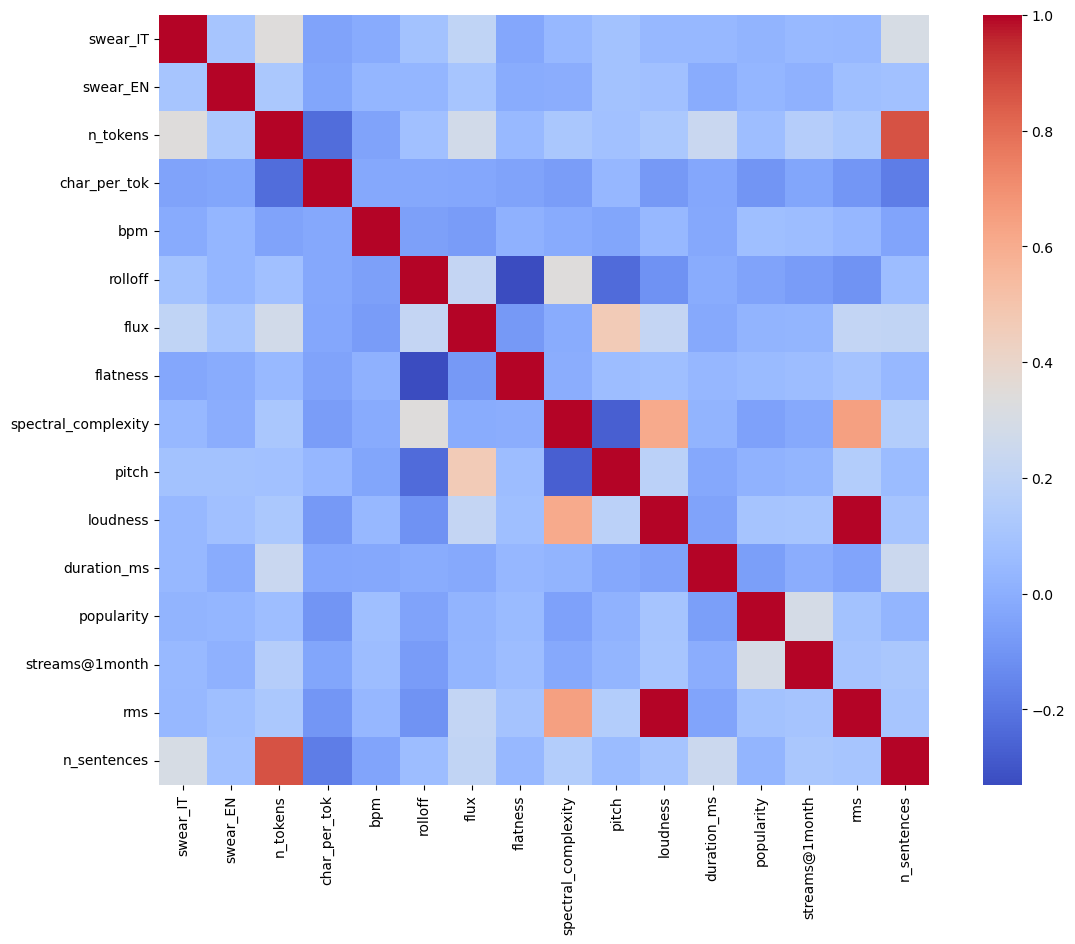

In [9]:
cols = [
    "swear_IT", "swear_EN",
    "n_tokens", "char_per_tok",
    "bpm", "rolloff", "flux", "flatness",
    "spectral_complexity", "pitch", "loudness",
    "duration_ms", "popularity", "streams@1month","rms", "n_sentences"
]

corr_matrix = df[cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", square=True, cbar=True)
plt.show()

In [10]:
#colonne tolte per correlazione 
#f.drop(columns=["rms", "n_sentences"], inplace=True)

In [11]:
# totgliamo album perchè strettamente correlato ad album_type
df.drop(columns=["album"], inplace=True)

In [12]:
# statistiche

cols = [
    "swear_IT", "swear_EN",
    "n_tokens", "char_per_tok",
    "bpm", "rolloff", "flux", "flatness",
    "spectral_complexity", "pitch", "loudness",
    "duration_ms", "popularity", "streams@1month",
]

stats_table = df[cols].describe().T
stats_table


,count,mean,std,min,25%,50%,75%,max
swear_IT,11166.0,2.343006,3.704831,0.0000,0.000000,1.000000,3.000000,7.200000e+01
swear_EN,11166.0,0.711177,2.555423,0.0000,0.000000,0.000000,0.000000,7.200000e+01
n_tokens,11090.0,496.891253,209.187612,3.0000,372.000000,491.000000,615.000000,3.089000e+03
char_per_tok,11090.0,4.054416,0.445958,2.0000,3.866946,4.012709,4.168686,1.200000e+01
bpm,11102.0,114.134841,26.827124,59.9700,91.910000,106.975000,134.650000,7.382700e+02
rolloff,11102.0,1616.965767,567.646409,0.0000,1222.457200,1551.018550,1935.570650,8.635954e+03
flux,11102.0,1.258893,0.137123,0.0000,1.172025,1.257100,1.346875,1.928500e+00
flatness,11102.0,0.859986,0.109106,0.1094,0.841400,0.882450,0.913075,1.000000e+00
spectral_complexity,11102.0,27.410247,8.441590,0.0000,21.881750,27.330850,32.978475,6.122250e+01
pitch,11102.0,2256.028782,382.134853,0.0000,2003.341325,2241.157450,2493.492250,3.993020e+03
